# Volatility is rough: replication and forecasting

Replication of Gatheral, Jaisson & Rosenbaum, *Volatility is Rough* (Quantitative Finance, 2018)
on 31 indices of the Oxford-Man Realized Library (2000-2022), an extension to 2026 with
range-based (Garman-Klass) variance from Yahoo Finance for 20 indices, and a walk-forward
forecasting competition (random walk, HAR, GARCH(1,1), the paper's RFSV predictor and
validation-selected improvements).

**Two data types are never mixed.** `rv` = 5-minute realized variance (Oxford-Man),
`gk` = Garman-Klass range variance (Yahoo). Every table says which one it uses.

Raw downloads are treated as untrusted data: they are parsed only by
`scripts/build_data.py`, which this notebook runs in a separate `python -I` process.

In [1]:
import os, sys, json, subprocess, time
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.data import load_processed
from src import estimation as ES, evaluation as E, models as M

RUN_PIPELINE = True        # False = reuse data/processed and results/ from a previous run
FIG, RES = ROOT / "figures", ROOT / "results"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_rows", 120)

# chart style: recessive grid, thin marks; categorical slots blue / orange / aqua
C1, C2, C3, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8f8e88", "axes.labelcolor": "#2b2b29", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "lines.linewidth": 1.6, "font.size": 9.5, "legend.frameon": False})

def run(script, *args):
    t = time.time()
    out = subprocess.run([sys.executable, "-I", str(ROOT / "scripts" / script), *args],
                         capture_output=True, text=True, cwd=str(ROOT / "scripts"))
    print(out.stdout[-3000:], out.stderr[-2000:], f"[{script}: {time.time()-t:.0f}s]")
    out.check_returncode()

## 1. Data

In [2]:
if RUN_PIPELINE or not (ROOT / "data/processed/rv.csv").exists():
    if not (ROOT / "data/raw/oxfordman.zip").exists():
        run("download_data.py")
    run("build_data.py")
rv = load_processed(ROOT / "data/processed/rv.csv")
gk = load_processed(ROOT / "data/processed/gk.csv")
qa = pd.read_csv(ROOT / "data/processed/data_quality.csv", index_col=0)
print(f"Oxford-Man RV: {len(rv)} indices; Garman-Klass (Yahoo): {len(gk)} indices")
qa

22-02-25  5652  2000-01-03  2026-10-12  6843.0         1.0         0.957             0.897     5645.0
FTMIB     2009-06-01  2022-02-25  3230         NaN         NaN     NaN         NaN           NaN               NaN        NaN
FTSE      2000-01-04  2022-02-25  5586  2000-01-04  2026-10-12  6764.0         0.0         0.933             0.849     5584.0
GDAXI     2000-01-03  2022-02-25  5614  2000-01-03  2026-10-12  6800.0         0.0         0.959             0.898     5611.0
GSPTSE    2002-05-02  2022-02-25  4953  2000-01-04  2026-10-09  6714.0        11.0         0.951             0.892     4952.0
HSI       2000-01-03  2022-02-25  5426  2000-01-03  2026-10-12  6597.0         0.0         0.946             0.858     5425.0
IBEX      2000-01-03  2022-02-25  5615  2000-01-03  2026-10-12  6812.0         0.0         0.952             0.878     5612.0
IXIC      2000-01-03  2022-02-25  5554  2000-01-03  2026-10-12  6734.0         0.0         0.954             0.914     5554.0
KS11      2000-0

Oxford-Man RV: 31 indices; Garman-Klass (Yahoo): 20 indices


,rv_start,rv_end,rv_n,gk_start,gk_end,gk_n,gk_dropped,corr_gk_park,corr_logrv_loggk,overlap_n
index,,,,,,,,,,
AEX,2000-01-03,2022-02-25,5650,2000-01-03,2026-10-12,6847.0,0.0,0.957670,0.878073,5646.0
AORD,2000-01-04,2022-02-25,5594,2000-01-04,2026-10-12,6767.0,5.0,0.910428,0.846167,5582.0
BFX,2000-01-03,2022-02-25,5648,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BSESN,2000-01-03,2022-02-25,5492,2000-01-03,2026-10-12,6601.0,0.0,0.959992,0.883979,5442.0
BVLG,2012-10-15,2022-02-25,2383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BVSP,2000-01-03,2022-02-25,5449,2000-01-03,2026-10-09,6635.0,0.0,0.911389,0.766555,5445.0
DJI,2000-01-03,2022-02-25,5549,2000-01-03,2026-10-12,6734.0,0.0,0.943244,0.891641,5549.0
FCHI,2000-01-03,2022-02-25,5652,2000-01-03,2026-10-12,6843.0,1.0,0.956869,0.897291,5645.0
FTMIB,2009-06-01,2022-02-25,3230,NaN,NaN,NaN,NaN,NaN,NaN,NaN


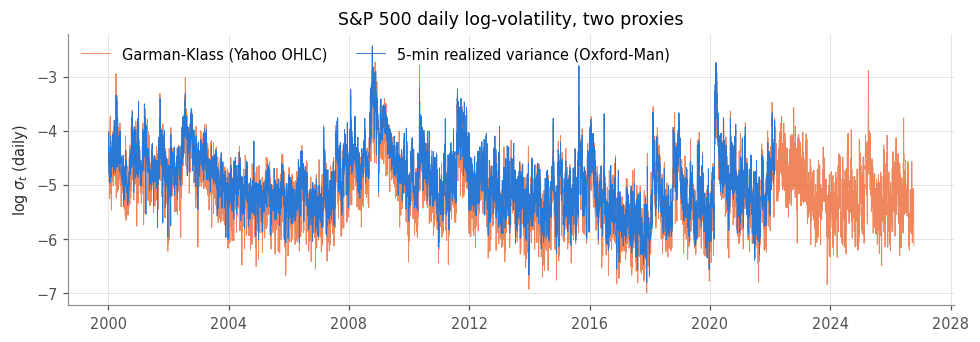

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(gk["SPX"].index, 0.5 * gk["SPX"].logv, color=C2, lw=0.6, alpha=0.8, label="Garman-Klass (Yahoo OHLC)")
ax.plot(rv["SPX"].index, 0.5 * rv["SPX"].logv, color=C1, lw=0.6, label="5-min realized variance (Oxford-Man)")
ax.set_ylabel(r"log $\sigma_t$ (daily)"); ax.set_title("S&P 500 daily log-volatility, two proxies")
ax.legend(loc="upper left", ncol=2)
fig.tight_layout(); fig.savefig(FIG / "spx_logvol.png"); plt.show()

## 2. Replication: smoothness of log-volatility

$m(q,\Delta) = \langle |\log\sigma_{t+\Delta} - \log\sigma_t|^q \rangle$ for $q\in\{0.5,1,1.5,2,3\}$,
$\Delta = 1..50$ trading days, with $\log\sigma_t = \tfrac12 \log \mathrm{RV}_t$.
If $\log\sigma$ behaves like fBm, $m(q,\Delta) \propto \Delta^{\zeta_q}$ with $\zeta_q = qH$.
$H$ = slope of $\zeta_q$ on $q$ through the origin. Standard errors: block bootstrap with
250-day blocks (500 draws), increments only inside blocks.

In [4]:
def h_table(series, tag):
    rows = []
    for name, df in series.items():
        x = ES.log_vol(df.logv.to_numpy())
        e = ES.estimate_h(x)
        boot = ES.block_bootstrap_h(x, block=250, n_boot=500, seed=1)
        r = {"data": tag, "index": name, "n": len(x), "start": df.index[0].date(), "end": df.index[-1].date(),
             "H": e["H"], "se": boot.std(ddof=1), "ci_lo": np.quantile(boot, .025), "ci_hi": np.quantile(boot, .975),
             "H_q2": e["H2"], "nu": e["nu"]}
        r.update({f"zeta/q (q={q:g})": z / q for q, z in zip(ES.QS, e["zeta"])})
        rows.append(r)
    return pd.DataFrame(rows)

H_rv, H_gk = h_table(rv, "rv"), h_table(gk, "gk")
Htab = pd.concat([H_rv, H_gk], ignore_index=True)
Htab.to_csv(RES / "h_table.csv", index=False)
Htab.round(3)

,data,index,n,start,end,H,se,ci_lo,ci_hi,H_q2,nu,zeta/q (q=0.5),zeta/q (q=1),zeta/q (q=1.5),zeta/q (q=2),zeta/q (q=3)
0,rv,AEX,5650,2000-01-03,2022-02-25,0.142,0.019,0.117,0.190,0.144,0.300,0.148,0.147,0.145,0.144,0.141
1,rv,AORD,5594,2000-01-04,2022-02-25,0.090,0.021,0.062,0.138,0.087,0.372,0.078,0.081,0.084,0.087,0.095
2,rv,BFX,5648,2000-01-03,2022-02-25,0.138,0.017,0.118,0.183,0.138,0.282,0.138,0.138,0.138,0.138,0.139
3,rv,BSESN,5492,2000-01-03,2022-02-25,0.120,0.010,0.095,0.131,0.121,0.320,0.126,0.125,0.123,0.121,0.118
4,rv,BVLG,2383,2012-10-15,2022-02-25,0.160,0.046,0.093,0.250,0.154,0.239,0.144,0.145,0.149,0.154,0.167
5,rv,BVSP,5449,2000-01-03,2022-02-25,0.133,0.016,0.104,0.164,0.134,0.307,0.136,0.135,0.135,0.134,0.132
6,rv,DJI,5549,2000-01-03,2022-02-25,0.136,0.020,0.103,0.180,0.136,0.360,0.136,0.136,0.136,0.136,0.136
7,rv,FCHI,5652,2000-01-03,2022-02-25,0.133,0.017,0.111,0.174,0.134,0.302,0.143,0.140,0.137,0.134,0.130
8,rv,FTMIB,3230,2009-06-01,2022-02-25,0.127,0.022,0.091,0.175,0.128,0.325,0.125,0.126,0.127,0.128,0.126
9,rv,FTSE,5586,2000-01-04,2022-02-25,0.111,0.014,0.095,0.149,0.113,0.348,0.118,0.116,0.114,0.113,0.110


In [5]:
def describe_h(t):
    return pd.Series({"indices": len(t), "median H": t.H.median(), "min H": t.H.min(), "max H": t.H.max(),
                      "median se": t.se.median(), "share in [0.10,0.15]": ((t.H >= .10) & (t.H <= .15)).mean(),
                      "median nu": t.nu.median()})
Hsum = pd.DataFrame({"rv (Oxford-Man, 2000-2022)": describe_h(H_rv), "gk (Yahoo, 2000-2026)": describe_h(H_gk)})
Hsum.round(3)

,"rv (Oxford-Man, 2000-2022)","gk (Yahoo, 2000-2026)"
indices,31.000,20.000
median H,0.126,0.077
min H,0.079,0.048
max H,0.171,0.094
median se,0.018,0.011
"share in [0.10,0.15]",0.806,0.000
median nu,0.320,0.467


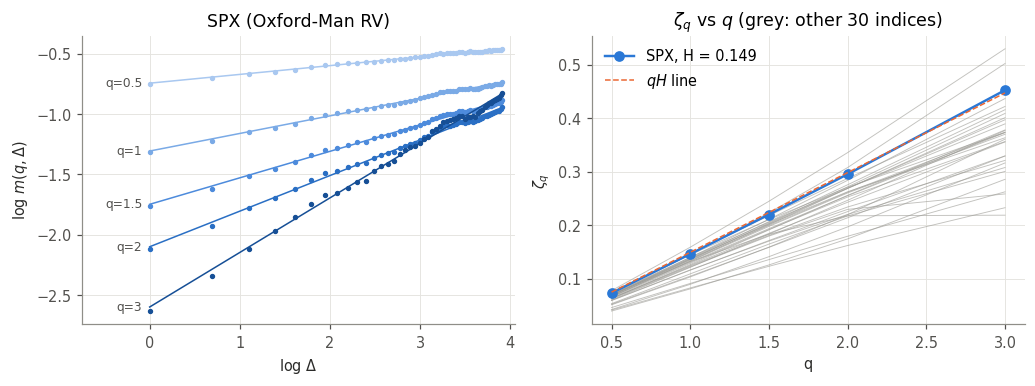

In [6]:
spx = ES.estimate_h(ES.log_vol(rv["SPX"].logv.to_numpy()))
blues = ["#a9c8f0", "#7aaae6", "#4d8bdc", "#2a6fc4", "#164f96"]   # sequential: light -> dark = small -> large q
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6))
ld = np.log(ES.LAGS)
zeta, icpt = ES.zeta_from_m(spx["m"])
for i, q in enumerate(ES.QS):
    axs[0].plot(ld, np.log(spx["m"][i]), "o", ms=2.5, color=blues[i])
    axs[0].plot(ld, icpt[i] + zeta[i] * ld, "-", lw=1, color=blues[i])
    axs[0].text(-0.08, icpt[i], f"q={q:g}", va="center", ha="right", fontsize=8, color="#52514e")
axs[0].set_xlabel(r"log $\Delta$"); axs[0].set_ylabel(r"log $m(q,\Delta)$"); axs[0].set_title("SPX (Oxford-Man RV)")
axs[0].set_xlim(-0.75, 4.05)
for name, df in rv.items():
    z = H_rv.set_index("index").loc[name]
    axs[1].plot(ES.QS, [z[f"zeta/q (q={q:g})"] * q for q in ES.QS], color=GREY, lw=0.6, alpha=0.6)
axs[1].plot(ES.QS, zeta, "o-", color=C1, label=f"SPX, H = {spx['H']:.3f}")
axs[1].plot(ES.QS, spx["H"] * ES.QS, "--", color=C2, lw=1, label=r"$qH$ line")
axs[1].set_xlabel("q"); axs[1].set_ylabel(r"$\zeta_q$"); axs[1].set_title(r"$\zeta_q$ vs $q$ (grey: other 30 indices)")
axs[1].legend()
fig.tight_layout(); fig.savefig(FIG / "scaling_spx.png"); plt.show()

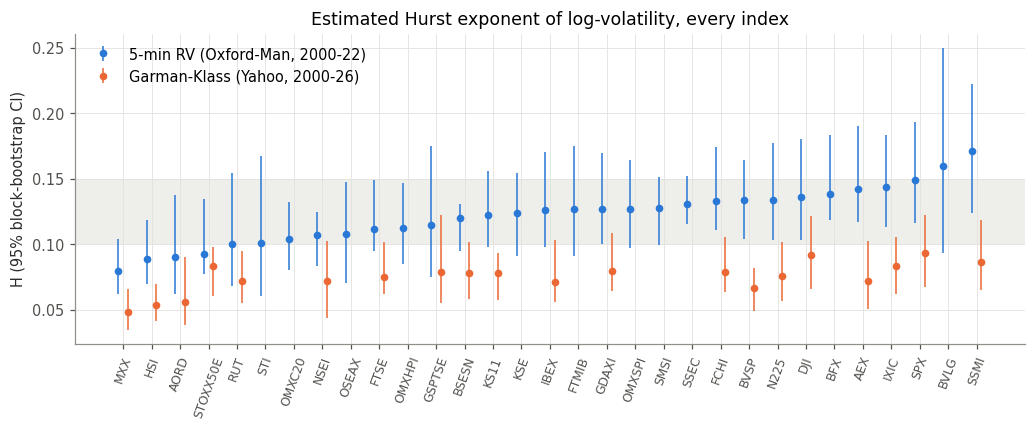

In [7]:
t = Htab.copy()
order = H_rv.sort_values("H")["index"].tolist()
order += [n for n in H_gk["index"] if n not in order]
fig, ax = plt.subplots(figsize=(9.5, 4))
for k, (tag, col, off) in enumerate([("rv", C1, -0.17), ("gk", C2, 0.17)]):
    s = t[t.data == tag].set_index("index").reindex(order)
    y = np.arange(len(order)) + off
    ax.errorbar(y, s.H, yerr=[s.H - s.ci_lo, s.ci_hi - s.H], fmt="o", ms=4, color=col, lw=1,
                label={"rv": "5-min RV (Oxford-Man, 2000-22)", "gk": "Garman-Klass (Yahoo, 2000-26)"}[tag])
ax.axhspan(0.10, 0.15, color="#e4e3df", alpha=0.6, lw=0)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=70, fontsize=8)
ax.set_ylabel("H (95% block-bootstrap CI)"); ax.set_title("Estimated Hurst exponent of log-volatility, every index")
ax.legend(loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "h_by_index.png"); plt.show()

### Are log-vol increments Gaussian at every lag?
The paper (Fig. 4) shows the distribution of $\log\sigma_{t+\Delta}-\log\sigma_t$ is close to
Gaussian for all $\Delta$. We show SPX and the skewness / excess kurtosis for every index.

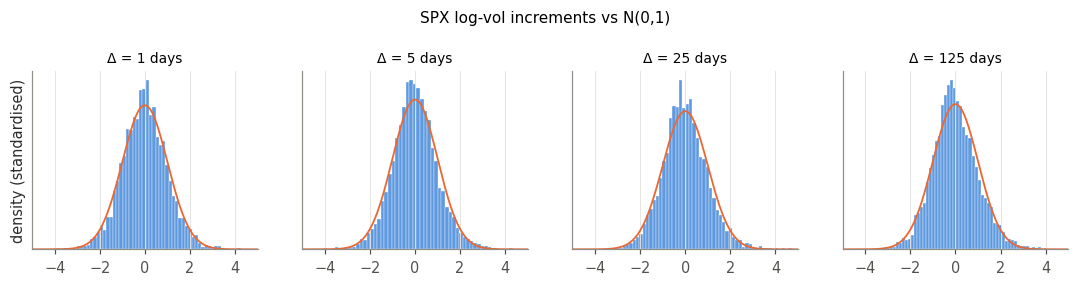

skew             exkurt            
           25%   50%   75%    25%   50%   75%
data lag                                     
gk   1    0.07  0.08  0.11   0.06  0.15  0.21
     5    0.06  0.08  0.10   0.26  0.38  0.49
     25   0.14  0.18  0.19   0.49  0.62  0.79
     125  0.09  0.14  0.19   0.26  0.44  0.58
rv   1    0.09  0.15  0.18   1.36  2.08  2.89
     5    0.13  0.19  0.24   1.21  1.70  2.43
     25   0.27  0.34  0.42   1.35  1.69  1.94
     125  0.19  0.25  0.31   0.70  0.78  1.21

In [8]:
x = ES.log_vol(rv["SPX"].logv.to_numpy())
lags = (1, 5, 25, 125)
fig, axs = plt.subplots(1, 4, figsize=(10, 2.6))
from scipy import stats
for ax, d in zip(axs, lags):
    inc = x[d:] - x[:-d]; z = (inc - inc.mean()) / inc.std()
    ax.hist(z, bins=60, density=True, color=C1, alpha=0.75, edgecolor="white", linewidth=0.3)
    g = np.linspace(-5, 5, 200); ax.plot(g, stats.norm.pdf(g), color=C2, lw=1.2)
    ax.set_title(f"Δ = {d} days", fontsize=9); ax.set_xlim(-5, 5); ax.set_yticks([])
axs[0].set_ylabel("density (standardised)")
fig.suptitle("SPX log-vol increments vs N(0,1)", fontsize=10); fig.tight_layout()
fig.savefig(FIG / "gauss_spx.png"); plt.show()

rows = []
for tag, ser in (("rv", rv), ("gk", gk)):
    for name, df in ser.items():
        mom = ES.increment_moments(ES.log_vol(df.logv.to_numpy()), lags)
        for d in lags:
            rows.append({"data": tag, "index": name, "lag": d, **mom[d]})
gauss = pd.DataFrame(rows); gauss.to_csv(RES / "increment_moments.csv", index=False)
gauss.groupby(["data", "lag"])[["skew", "exkurt"]].describe().loc[:, (slice(None), ["25%", "50%", "75%"])].round(2)

### Smoothing bias
Realized variance measures the *integrated* variance over a day, not the spot variance.
We simulate $\log\sigma_t = \nu W^H_t$ ($\nu = 0.3$, 50 steps per day, 5000 days), and estimate $H$
(i) from spot log-vol at day ends, (ii) from the log of daily integrated variance,
(iii) from (ii) plus i.i.d. measurement noise with s.d. 0.25 on log variance (a crude stand-in for RV
estimation error; range estimators are noisier). Three seeds each.

In [9]:
rows = []
for Htrue in (0.05, 0.10, 0.15, 0.20, 0.30, 0.50):
    for seed in range(3):
        spot, liv = ES.simulate_rfsv(5000, Htrue, 0.3, steps_per_day=50, seed=seed)
        noisy = liv + 0.5 * np.random.default_rng(100 + seed).normal(0, 0.25, len(liv))
        rows.append({"H_true": Htrue, "seed": seed, "H_spot": ES.estimate_h(spot)["H"],
                     "H_integrated": ES.estimate_h(liv)["H"], "H_integrated+noise": ES.estimate_h(noisy)["H"]})
sim = pd.DataFrame(rows); sim.to_csv(RES / "smoothing_bias.csv", index=False)
sim_s = sim.groupby("H_true")[["H_spot", "H_integrated", "H_integrated+noise"]].mean()
sim_s.round(3)

,H_spot,H_integrated,H_integrated+noise
H_true,,,
0.05,0.048,0.159,0.081
0.10,0.096,0.195,0.131
0.15,0.144,0.231,0.176
0.20,0.194,0.269,0.219
0.30,0.295,0.350,0.309
0.50,0.500,0.529,0.499


## 3. Forecasting competition

Walk-forward, one forecast per day per index; burn-in of 1000 days; parameters re-estimated
every 20 days on past data only (H and ν of RFSV; GARCH; calibration offsets), HAR-type
regressions refitted every day on all past (feature, target) pairs whose target is already observed.
Horizons h = 1, 5, 20; target $\log v_{t+h}$ (point target, as in the paper).

* **validation**: targets dated ≤ 2014-12-31 — used to pick one improved model per horizon.
* **test**: origins dated ≥ 2015-01-01 (to 2022-02-25 for `rv`, to 2026-10 for `gk`) — used once.

Losses: MSE of the log-variance forecast (ratios are identical for log-vol) and QLIKE on the
variance forecast. All models are scored on the same days.

In [10]:
if RUN_PIPELINE or not (RES / "forecasts_rv.parquet").exists():
    run("run_forecasts.py")
print((RES / "lookahead_check.txt").read_text())
long = {tag: pd.read_parquet(RES / f"forecasts_{tag}.parquet") for tag in ("rv", "gk")}
lt = {tag: E.loss_table(d) for tag, d in long.items()}
pd.concat([v.assign(data=k) for k, v in lt.items()]).to_csv(RES / "loss_table.csv", index=False)

check_no_lookahead(SPX[:2500], cut=1800): PASSED
Every observation after day 1800 was perturbed; all forecasts made at origins <= 1800 were identical for every model and horizon.
 (7s)
rv: 31 indices, 4,537,128 rows, 85s
gk: 20 indices, 3,964,296 rows, 82s
  [run_forecasts.py: 176s]
check_no_lookahead(SPX[:2500], cut=1800): PASSED
Every observation after day 1800 was perturbed; all forecasts made at origins <= 1800 were identical for every model and horizon.



### 3.1 Validation period: which improvement is selected (by log-MSE ratio to HAR, geometric mean over indices)

In [11]:
sel = {tag: E.select_models(lt[tag]) for tag in lt}
print("selected on validation:", sel)
for tag in lt:
    v = E.ratio_summary(lt[tag], "val")
    print(f"\n[{tag}] validation, loss / HAR loss (geometric mean over indices)")
    print(v.pivot(index="model", columns="h", values=["gm_ratio_mse", "gm_ratio_qlike"]).round(3))

selected on validation: {'rv': {1: 'HAR-L-RFSV', 5: 'COMB(RFSV,HAR-L)', 20: 'RFSV-roll250'}, 'gk': {1: 'HAR-L-RFSV', 5: 'HAR-L-RFSV', 20: 'COMB(RFSV,HAR-L)'}}

[rv] validation, loss / HAR loss (geometric mean over indices)
                 gm_ratio_mse               gm_ratio_qlike              
h                          1      5      20             1      5      20
model                                                                   
COMB(RFSV,HAR)          0.996  0.990  0.980          0.992  0.989  0.982
COMB(RFSV,HAR-L)        0.942  0.979  0.978          0.936  0.977  0.980
GARCH                   1.346  1.193  1.194          1.288  1.149  1.102
HAR                     1.000  1.000  1.000          1.000  1.000  1.000
HAR-L                   0.942  0.987  1.000          0.937  0.982  1.002
HAR-L-RFSV              0.935  0.982  1.017          0.929  0.981  1.024
HAR-RFSV                0.993  0.994  1.012          0.994  0.999  1.011
RFSV                    1.027  0.994  0.979    

### 3.2 Held-out test period

In [12]:
def headline(tag):
    s = E.ratio_summary(lt[tag], "test")
    d = lt[tag][lt[tag].period == "test"]
    rows = []
    for h in E.HS:
        best = sel[tag][h]
        for lab, m in [("RW", "RW"), ("GARCH", "GARCH"), ("HAR", "HAR"), ("RFSV (paper)", "RFSV"), (f"Selected: {best}", best)]:
            r = s[(s.h == h) & (s.model == m)].iloc[0]
            mm = d[(d.h == h) & (d.model == m)]
            rows.append({"data": tag, "h": h, "model": lab, "mean MSE(log v)": mm.mse_log.mean(),
                         "MSE / HAR": r.gm_ratio_mse, "beats HAR (MSE)": f"{r.wins_mse}/{r.n_index}",
                         "mean QLIKE": mm.qlike.mean(), "QLIKE / HAR": r.gm_ratio_qlike,
                         "beats HAR (QLIKE)": f"{r.wins_qlike}/{r.n_index}"})
    return pd.DataFrame(rows)
head = pd.concat([headline("rv"), headline("gk")], ignore_index=True)
head.to_csv(RES / "test_headline.csv", index=False)
head.round(3)

,data,h,model,mean MSE(log v),MSE / HAR,beats HAR (MSE),mean QLIKE,QLIKE / HAR,beats HAR (QLIKE)
0,rv,1,RW,0.429,1.338,0/31,0.319,1.458,0/31
1,rv,1,GARCH,0.423,1.333,0/31,0.252,1.302,0/31
2,rv,1,HAR,0.320,1.000,0/31,0.197,1.000,0/31
3,rv,1,RFSV (paper),0.328,1.024,5/31,0.199,1.009,13/31
4,rv,1,Selected: HAR-L-RFSV,0.300,0.941,31/31,0.186,0.946,29/31
5,rv,5,RW,0.649,1.391,0/31,0.498,1.534,0/31
6,rv,5,GARCH,0.546,1.179,0/31,0.351,1.147,2/31
7,rv,5,HAR,0.467,1.000,0/31,0.308,1.000,0/31
8,rv,5,RFSV (paper),0.467,1.001,17/31,0.310,1.002,15/31
9,rv,5,"Selected: COMB(RFSV,HAR-L)",0.458,0.982,31/31,0.304,0.985,26/31


In [13]:
for tag in lt:
    s = E.ratio_summary(lt[tag], "test")
    print(f"\n[{tag}] TEST, all models incl. non-selected candidates (for transparency only; selection was made on validation)")
    print(s.pivot(index="model", columns="h", values=["gm_ratio_mse", "gm_ratio_qlike"]).round(3))


[rv] TEST, all models incl. non-selected candidates (for transparency only; selection was made on validation)
                 gm_ratio_mse               gm_ratio_qlike              
h                          1      5      20             1      5      20
model                                                                   
COMB(RFSV,HAR)          0.996  0.993  0.991          0.992  0.994  1.057
COMB(RFSV,HAR-L)        0.952  0.982  0.987          0.952  0.985  1.051
GARCH                   1.333  1.179  1.152          1.302  1.147  0.983
HAR                     1.000  1.000  1.000          1.000  1.000  1.000
HAR-L                   0.954  0.987  0.992          0.957  0.990  0.999
HAR-L-RFSV              0.941  0.973  0.975          0.946  0.998  1.036
HAR-RFSV                0.990  0.989  0.981          0.993  1.009  1.036
RFSV                    1.024  1.001  0.996          1.009  1.002  1.079
RFSV-roll1000           1.025  1.005  0.999          1.011  1.009  1.097
RFSV-roll250 

### 3.3 Diebold-Mariano tests (test period, per index)
HAC (Bartlett, lag = max(h, 4(T/100)^{2/9})) DM statistic on loss differentials; 5% level.
Counts = number of indices where model A is significantly better / worse than B.
A Model Confidence Set was not run (cost/complexity); pairwise DM tests are reported instead.

In [14]:
dms = []
for tag in long:
    d = long[tag][long[tag].period == "test"]
    pairs = [("RFSV", "HAR"), ("RFSV", "RW"), ("RFSV", "GARCH"), ("HAR", "GARCH")]
    pairs += [(m, "HAR") for m in sorted(set(sel[tag].values()))] + [(m, "RFSV") for m in sorted(set(sel[tag].values()))]
    dm = E.dm_table(d, pairs, "test").assign(data=tag)
    dms.append(dm)
dm = pd.concat(dms, ignore_index=True); dm.to_csv(RES / "dm_tests.csv", index=False)
cnt = pd.concat([E.dm_counts(dm[dm.data == t]).assign(data=t) for t in long], ignore_index=True)
# keep only the selected model rows at their own horizon
keep = cnt.A.isin(["RFSV", "HAR"]) | cnt.apply(lambda r: sel[r.data].get(int(r.h)) == r.A, axis=1)
cnt = cnt[keep]; cnt.to_csv(RES / "dm_counts.csv", index=False)
cnt.set_index(["data", "A", "B", "h"])

A_better_mse  A_worse_mse  n_mse  A_better_qlike  A_worse_qlike  n_qlike
data A                B     h                                                                           
rv   COMB(RFSV,HAR-L) HAR   5             21            0     31              10              0       31
                      RFSV  5             19            0     31               9              0       31
     HAR              GARCH 1             31            0     31              30              0       31
                            5             30            0     31              20              0       31
                            20            17            0     31               3              0       31
     HAR-L-RFSV       HAR   1             29            0     31              22              0       31
                      RFSV  1             30            0     31              20              0       31
     RFSV             GARCH 1             31            0     31              23              0       31
                            5             28            0     31              18              0       31
                            20            13            0     31               1              0       31
                      HAR   1              2           17     31               2              6       31
                            5              0            4     31               1              0       31
                            20             0            0     31               1              0       31
                      RW    1             31            0     31              30              0       31
                            5             31            0     31              30              0       31
                            20            31            0     31              27              0       31
     RFSV-roll250     HAR   20             0            1     31               0              4       31
                      RFSV  20             0            8     31               0             14       31
gk   COMB(RFSV,HAR-L) HAR   20             6            0     20               0              0       20
                      RFSV  20             4            0     20               2              0       20
     HAR              GARCH 1             20            0     20              16              0       20
                            5             20            0     20               6              0       20
                            20            18            0     20               1              0       20
     HAR-L-RFSV       HAR   1             20            0     20              20              0       20
                            5             18            0     20               6              0       20
                      RFSV  1             20            0     20              19              0       20
                            5             18            0     20              12              0       20
     RFSV             GARCH 1             13            0     20               8              0       20
                            5             16            0     20               2              0       20
                            20            14            0     20               0              0       20
                      HAR   1              0           18     20               0              8       20
                            5              0            4     20               0              1       20
                            20             1            1     20               0              0       20
                      RW    1             20            0     20              19              0       20
                            5             20            0     20              19              0       20
                            20            20            0     20              17              0       20

In [15]:
# per-index test-period table: log-MSE ratio to HAR for RFSV and the selected model
rows = []
for tag in lt:
    d = lt[tag][lt[tag].period == "test"].set_index(["index", "h", "model"])
    for (idx, h), _ in d.groupby(level=[0, 1]):
        har = d.loc[(idx, h, "HAR")]
        r = {"data": tag, "index": idx, "h": h}
        for lab, m in [("RFSV", "RFSV"), ("selected", sel[tag][h])]:
            r[f"{lab} MSE/HAR"] = d.loc[(idx, h, m)].mse_log / har.mse_log
            r[f"{lab} QLIKE/HAR"] = d.loc[(idx, h, m)].qlike / har.qlike
        q = dm[(dm.data == tag) & (dm["index"] == idx) & (dm.h == h)].set_index(["A", "B"])
        r["p DM RFSV-HAR (MSE)"] = q.loc[("RFSV", "HAR")].p_mse
        r["p DM sel-HAR (MSE)"] = q.loc[(sel[tag][h], "HAR")].p_mse
        rows.append(r)
per_index = pd.DataFrame(rows); per_index.to_csv(RES / "test_per_index.csv", index=False)
per_index.pivot_table(index=["data", "index"], columns="h",
                      values=["RFSV MSE/HAR", "selected MSE/HAR"]).round(3)

RFSV MSE/HAR               selected MSE/HAR              
h                       1      5      20               1      5      20
data index                                                             
gk   AEX             1.077  1.019  0.999            0.935  0.949  0.984
     AORD            1.088  1.037  1.001            0.946  0.971  0.987
     BSESN           1.074  1.018  0.970            0.917  0.966  0.964
     BVSP            1.086  1.024  0.991            0.963  0.969  0.975
     DJI             1.009  1.011  1.012            0.926  0.967  1.000
     FCHI            1.044  1.002  0.989            0.924  0.945  0.983
     FTSE            1.080  1.013  0.990            0.927  0.957  0.983
     GDAXI           1.068  1.005  0.989            0.925  0.946  0.979
     GSPTSE          1.035  1.015  0.996            0.926  0.961  0.990
     HSI             1.082  1.002  0.990            0.953  0.982  0.987
     IBEX            1.047  1.005  0.984            0.931  0.949  0.980
     IXIC            1.030  1.008  1.002            0.926  0.971  0.995
     KS11            1.064  1.002  0.962            0.948  0.989  0.962
     MXX             1.106  1.061  1.022            0.966  0.982  0.999
     N225            1.043  1.016  1.009            0.938  0.983  1.000
     NSEI            1.077  1.021  0.985            0.908  0.971  0.984
     RUT             1.052  1.020  1.015            0.938  0.971  0.998
     SPX             1.004  1.007  1.013            0.910  0.962  0.998
     SSMI            1.068  1.012  1.005            0.926  0.965  0.993
     STOXX50E        1.047  1.007  0.996            0.926  0.944  0.983
rv   AEX             1.035  0.999  0.998            0.948  0.980  1.000
     AORD            1.030  1.017  0.995            0.907  0.975  1.008
     BFX             1.036  1.005  1.012            0.939  0.984  1.024
     BSESN           1.030  0.993  0.964            0.939  0.984  0.978
     BVLG            1.029  0.974  0.940            0.969  0.974  0.956
     BVSP            1.019  1.018  1.040            0.970  0.994  1.059
     DJI             0.970  0.997  1.014            0.926  0.980  1.041
     FCHI            1.034  0.994  0.998            0.945  0.982  1.004
     FTMIB           1.024  0.991  0.991            0.945  0.983  1.002
     FTSE            1.069  1.020  1.006            0.924  0.977  1.010
     GDAXI           1.033  0.992  0.987            0.945  0.973  0.996
     GSPTSE          0.978  0.995  0.988            0.944  0.979  1.017
     HSI             1.030  0.989  0.999            0.945  0.980  1.001
     IBEX            1.027  0.991  0.991            0.957  0.982  1.004
     IXIC            0.993  1.002  1.006            0.943  0.990  1.025
     KS11            1.033  0.995  0.961            0.924  0.982  0.978
     KSE             1.036  0.997  0.983            0.935  0.982  0.976
     MXX             1.070  1.028  1.018            0.964  0.993  1.023
     N225            1.021  1.006  1.003            0.943  0.991  1.015
     NSEI            1.028  1.001  0.980            0.943  0.994  0.993
     OMXC20          1.057  1.023  1.013            0.966  0.999  1.017
     OMXHPI          1.017  1.001  0.979            0.937  0.983  0.991
     OMXSPI          1.029  1.003  1.004            0.907  0.982  1.012
     OSEAX           1.069  1.025  1.017            0.940  0.979  1.024
     RUT             0.987  1.000  1.024            0.907  0.974  1.045
     SMSI            1.012  0.995  1.003            0.969  0.986  1.012
     SPX             0.967  0.998  1.015            0.932  0.982  1.041
     SSEC            1.016  1.004  1.001            0.923  0.987  1.006
     SSMI            1.022  1.001  1.008            0.949  0.975  1.026
     STI             1.018  0.973  0.947            0.968  0.969  0.966
     STOXX50E        1.031  0.994  1.006            0.927  0.963  1.010

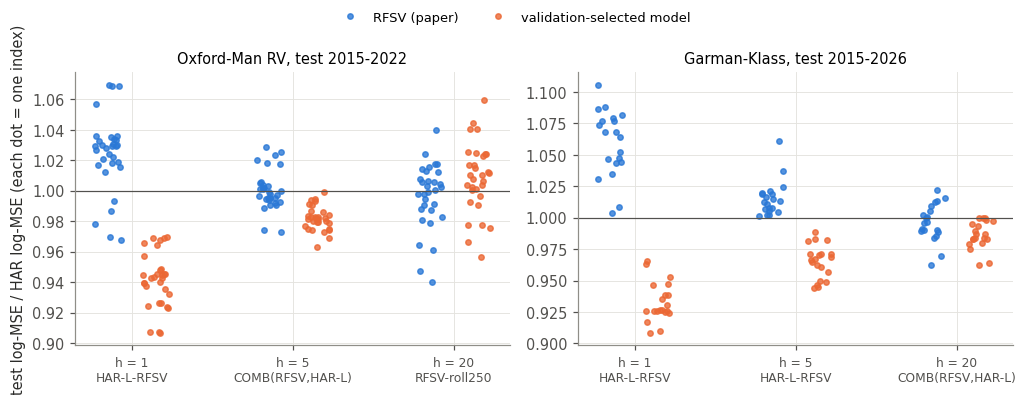

In [16]:
fig, axs = plt.subplots(1, 2, figsize=(9.5, 3.6), sharey=False)
for ax, tag in zip(axs, ("rv", "gk")):
    p = per_index[per_index.data == tag]
    for j, h in enumerate(E.HS):
        q = p[p.h == h]
        jit = np.random.default_rng(j).uniform(-0.08, 0.08, len(q))
        ax.plot(j - 0.15 + jit, q["RFSV MSE/HAR"], "o", ms=3.5, color=C1, alpha=0.8, label="RFSV (paper)" if j == 0 else None)
        ax.plot(j + 0.15 + jit, q["selected MSE/HAR"], "o", ms=3.5, color=C2, alpha=0.8, label="validation-selected model" if j == 0 else None)
    ax.axhline(1, color="#52514e", lw=0.8)
    ax.set_xticks(range(3)); ax.set_xticklabels([f"h = {h}\n{sel[tag][h]}" for h in E.HS], fontsize=8)
    ax.set_title({"rv": "Oxford-Man RV, test 2015-2022", "gk": "Garman-Klass, test 2015-2026"}[tag], fontsize=9.5)
axs[0].set_ylabel("test log-MSE / HAR log-MSE (each dot = one index)")
fig.legend(*axs[0].get_legend_handles_labels(), loc="upper center", ncol=2, fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.savefig(FIG / "test_ratios.png"); plt.show()

### 3.4 Calibration of the variance forecasts (why QLIKE ranks differ from MSE ranks)
For each index: mean of $v_{t+h}/\hat v_{t+h}$ on the test period (1 = unbiased level, < 1 = forecast too high);
the table shows the median across indices.

In [17]:
rows = []
for tag, d in long.items():
    d = d[d.period == "test"].assign(ratio=lambda x: np.exp(x.y.astype(float)) / x.f_var.astype(float))
    per = d.groupby(["index", "h", "model"]).ratio.mean().groupby(["h", "model"]).median()
    rows.append(per.unstack(0).assign(data=tag))
bias = pd.concat(rows); bias.to_csv(RES / "variance_calibration.csv")
bias.round(3)

h,1,5,20,data
model,,,,
"COMB(RFSV,HAR)",1.035,1.075,1.271,rv
"COMB(RFSV,HAR-L)",1.025,1.071,1.268,rv
GARCH,1.004,1.078,1.087,rv
HAR,1.029,1.059,1.174,rv
HAR-L,1.019,1.062,1.197,rv
HAR-L-RFSV,1.039,1.091,1.304,rv
HAR-RFSV,1.043,1.085,1.262,rv
RFSV,1.057,1.097,1.289,rv
RFSV-roll1000,1.050,1.088,1.292,rv


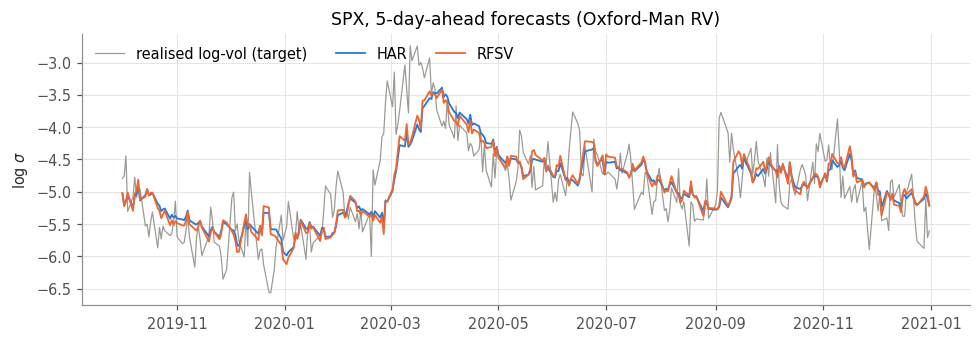

In [18]:
# SPX example: 5-day-ahead log-vol forecasts around 2020
d = long["rv"]; d = d[(d["index"] == "SPX") & (d.h == 5)]
piv = d.pivot(index="target", columns="model", values="f_log").loc["2019-10-01":"2020-12-31"]
yv = d[d.model == "HAR"].set_index("target").y.loc["2019-10-01":"2020-12-31"]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(yv.index, 0.5 * yv, color=GREY, lw=0.8, label="realised log-vol (target)")
ax.plot(piv.index, 0.5 * piv.HAR, color=C1, lw=1.2, label="HAR")
ax.plot(piv.index, 0.5 * piv.RFSV, color=C2, lw=1.2, label="RFSV")
ax.set_ylabel(r"log $\sigma$"); ax.set_title("SPX, 5-day-ahead forecasts (Oxford-Man RV)"); ax.legend(ncol=3, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "spx_forecast_2020.png"); plt.show()

In [19]:
# key numbers for README / report / CV
summary = {
    "n_indices_rv": len(rv), "n_indices_gk": len(gk),
    "H_rv_median": float(H_rv.H.median()), "H_rv_min": float(H_rv.H.min()), "H_rv_max": float(H_rv.H.max()),
    "H_gk_median": float(H_gk.H.median()), "H_spx_rv": float(H_rv.set_index("index").loc["SPX", "H"]),
    "H_spx_rv_se": float(H_rv.set_index("index").loc["SPX", "se"]),
    "selected": {k: {str(h): m for h, m in v.items()} for k, v in sel.items()},
    "headline": head.to_dict(orient="records"),
}
(RES / "summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(json.dumps({k: v for k, v in summary.items() if k != "headline"}, indent=1, default=str))

{
 "n_indices_rv": 31,
 "n_indices_gk": 20,
 "H_rv_median": 0.1261808543992941,
 "H_rv_min": 0.07925501245290723,
 "H_rv_max": 0.17111736402151423,
 "H_gk_median": 0.07666123749517971,
 "H_spx_rv": 0.1490117011878568,
 "H_spx_rv_se": 0.02055017799270612,
 "selected": {
  "rv": {
   "1": "HAR-L-RFSV",
   "5": "COMB(RFSV,HAR-L)",
   "20": "RFSV-roll250"
  },
  "gk": {
   "1": "HAR-L-RFSV",
   "5": "HAR-L-RFSV",
   "20": "COMB(RFSV,HAR-L)"
  }
 }
}
